In [7]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

#  Copyright (c) 2021 - 2022.  FlexibleLecture@Linkedin
#  All rights reserved.

# Created By  : FlexibleLecture@Linkedin
# Created Date: 5/14/2022
# version ='1.0'

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import sys
import math
import time
from scipy.linalg import cholesky_banded, cho_solve_banded, solveh_banded, cho_factor, cho_solve

In [9]:
class ProblemOne:
    def __init__(self):
        return

    def define_problem(k, n):
        P_l = []
        for _ in range(n - k):
            B = np.random.rand(k + 1, k + 1)
            P_l.append(B.T @ B)

        Pext_l = []
        Pext_l.append(np.block([[P_l[0], np.zeros((k + 1, (n - k - 1)))],
                                [np.zeros((n - k - 1, k + 1)), np.zeros((n - k - 1, (n - k - 1)))]]))

        for i in range(1, n - k - 1):
            Pext = np.block([[np.zeros((i, i)), np.zeros((i, k + 1)), np.zeros((i, (n - i - k - 1)))],
                             [np.zeros((k + 1, i)), P_l[i], np.zeros((k + 1, (n - i - k - 1)))],
                             [np.zeros((n - i - k - 1, i)), np.zeros((n - i - k - 1, k + 1)),
                              np.zeros((n - i - k - 1, (n - i - k - 1)))]])
            Pext_l.append(Pext)

        Pext_l.append(np.block([[np.zeros((n - k - 1, n - k - 1)), np.zeros((n - k - 1, k + 1))],
                                [np.zeros((k + 1, n - k - 1)), P_l[n - k - 1]]]))

        P = np.zeros((n, n))
        for i in range(n - k):
            if not np.all(np.linalg.eigvals(Pext_l[i]) >= 0):
                raise RuntimeError("The hessian should be semi positive definite")
            P = P + Pext_l[i]

        return P

    def my_f(x, P):
        return 0.5 * (x.T @ P @ x).item()

    def my_gradient_f(x, P):
        gradient = P @ x
        return gradient

    def my_hessian_f(x, P):
        hessian = P
        return hessian

    def my_newton_step_decrement(k, n, x, args):
        gradient = ProblemOne.my_gradient_f(x, *args)
        hessian = ProblemOne.my_hessian_f(x, *args)
        if np.linalg.cond(hessian) < 1 / sys.float_info.epsilon:
            hessian_inv = np.linalg.inv(hessian)
            x_nt = -1 * hessian_inv @ gradient
            decrement = -1 * gradient.T @ x_nt
            return x_nt, decrement.item()
        else:
            raise RuntimeError("inversion of hessian failed")

    def my_newton_step_decrement_opt(k, n, x, args):
        gradient = ProblemOne.my_gradient_f(x, *args)
        hessian = ProblemOne.my_hessian_f(x, *args)

        if np.linalg.cond(hessian) < 1 / sys.float_info.epsilon:
            A = hessian
            Ab_lower = np.zeros((k + 1, n))
            Ab_lower[0, :] = np.diag(A, k=0)
            for i in range(1, k + 1):
                Ab_lower[i, :] = np.block([np.diag(A, k=i), np.zeros((1, i))])

            c = cholesky_banded(Ab_lower, lower=True)
            x_nt = -1 * cho_solve_banded((c, True), gradient)

            decrement = -1 * gradient.T @ x_nt
            return x_nt, decrement.item()
        else:
            raise RuntimeError("inversion of hessian failed")

    def backtracking_line_search(f, df, x, delta_x, alpha, beta, args):
        t = 1
        try:
            while f(x + delta_x * t, *args) > f(x, *args) + alpha * t * ((df(x, *args).T @ delta_x).item()):
                t = beta * t
            return t
        except:
            print('Error')

    def plot_profiling_comparison(k_s, n, n_seeds, ax):
        elapse_time_log = np.zeros((len(k_s), 2, n_seeds))
        for k_i, k in enumerate(k_s):
            methods = [ProblemOne.my_newton_step_decrement, ProblemOne.my_newton_step_decrement_opt]
            for method_i, newton_step_decrement_f in enumerate(methods):
                for seed in range(n_seeds):
                    #print('[{}, {}, seed={}]'.format(k_i, method_i, seed))
                    np.random.seed(seed)
                    P = ProblemOne.define_problem(k, n)
                    if not np.all(np.linalg.eigvals(P) > 0):
                        raise RuntimeError("The hessian should be positive definite")

                    args = (P,)
                    epsilon = 1e-10
                    alpha = 0.01
                    beta = 0.5
                    start_time = time.time()
                    # backtracking line search
                    x0 = 100 * np.ones((n, 1))
                    x = x0
                    x_nt, decrement = newton_step_decrement_f(k, n, x, args)
                    fx = []
                    tx = []
                    fx.append(ProblemOne.my_f(x, *args))
                    iteration = 0

                    while decrement / 2 > epsilon:
                        t = ProblemOne.backtracking_line_search(ProblemOne.my_f,
                                                                ProblemOne.my_gradient_f,
                                                                x, x_nt, alpha, beta, args)
                        tx.append(t)
                        x_next = x + t * x_nt
                        x = x_next

                        x_nt, decrement = newton_step_decrement_f(k, n, x, args)
                        fx.append(ProblemOne.my_f(x, *args))
                        iteration = iteration + 1

                    stop_time = time.time()
                    elapse_time = stop_time - start_time
                    elapse_time_log[k_i, method_i, seed] = elapse_time
                    #print("--- %s seconds ---" % elapse_time)

        elapse_time_avg = np.average(elapse_time_log, axis=2)
        #print(elapse_time_avg)

        ax.semilogx(k_s, elapse_time_avg[:, 0], marker='s', fillstyle='none', base=2, linestyle='dashed',
                    label='without exploiting the structure')
        ax.semilogx(k_s, elapse_time_avg[:, 1], marker='o', fillstyle='none', linestyle='dashed', base=2,
                    label='exploiting the band structure')
        ax.grid()
        ax.legend()
        ax.set_xlabel('p')
        ax.set_ylabel('elapse time (second)')
        ax.set_title('Elapse time for the Newton method')

In [10]:
class ProblemTwo:
    def __init__(self):
        return

    def define_problem(n, k, m, x_p):
        A = np.zeros((n - k, m, n))
        b = np.zeros((n - k, m, 1))
        scaler = 0.1
        Akk = scaler * np.random.uniform(-1, 1, (m, k + 1))
        A[0] = np.block([Akk, np.zeros((m, n - k - 1))])
        b[0] = -A[0] @ x_p
        for i in range(1, n - k - 1):
            Akk = scaler * np.random.uniform(-1, 1, (m, k + 1))
            A[i] = np.block([np.zeros((m, i)), Akk, np.zeros((m, n - k - 1 - i))])
            b[i] = -A[i] @ x_p
        A[n - k - 1] = np.block([np.zeros((m, n - k - 1)), Akk])
        return A, b

    def my_f(x, n, k, m, A, b):
        psi = 0
        for i in range(n - k):
            yi = A[i] @ x + b[i]
            eta_i = 0.5 * (yi.T @ yi).item()
            psi_i = math.exp(eta_i)
            psi = psi + psi_i
        return psi

    def my_gradient_f(x, n, k, m, A, b):
        g = np.zeros((n, 1))
        for i in range(n - k):
            yi = A[i] @ x + b[i]
            eta_i = 0.5 * (yi.T @ yi).item()
            g_i = math.exp(eta_i) * (A[i].T @ (yi))
            g = g + g_i
        return g

    def my_hessian_f(x, n, k, m, A, b):
        h = np.zeros((n, n))
        for i in range(n - k):
            yi = A[i] @ x + b[i]
            eta_i = 0.5 * (yi.T @ yi).item()
            h_i = math.exp(eta_i) * ((A[i].T @ A[i]) + (A[i].T @ yi @ yi.T @ A[i]))
            h = h + h_i
        return h

    def my_newton_step_decrement(x, args):
        gradient = ProblemTwo.my_gradient_f(x, *args)
        hessian = ProblemTwo.my_hessian_f(x, *args)
        if np.linalg.cond(hessian) < 1 / sys.float_info.epsilon:
            hessian_inv = np.linalg.inv(hessian)
            x_nt = -1 * hessian_inv @ gradient
            # x_nsd = ((gradient.T @ hessian_inv @ gradient).item() ** (-1/2)) * x_nt
            decrement = -1 * gradient.T @ x_nt
            return x_nt, decrement.item()
        else:
            raise RuntimeError("inversion of hessian failed")

    def my_newton_step_decrement_opt(x, args):
        gradient = ProblemTwo.my_gradient_f(x, *args)
        hessian = ProblemTwo.my_hessian_f(x, *args)

        if np.linalg.cond(hessian) < 1 / sys.float_info.epsilon:
            A = hessian

            c, low = cho_factor(A)
            x_nt = -1 * cho_solve((c, low), gradient)

            decrement = -1 * gradient.T @ x_nt
            return x_nt, decrement.item()
        else:
            raise RuntimeError("inversion of hessian failed")

    def backtracking_line_search(f, df, x, delta_x, alpha, beta, args):
        t = 1
        try:
            while f(x + delta_x * t, *args) > f(x, *args) + alpha * t * ((df(x, *args).T @ delta_x).item()):
                t = beta * t
            return t
        except:
            print('Error')

    def plot_profiling_comparison(k_s, m, n, n_seeds, ax):
        x_p = np.ones((n, 1))
        methods = [ProblemTwo.my_newton_step_decrement,
                   ProblemTwo.my_newton_step_decrement_opt]
        elapse_time_log = np.zeros((len(k_s), 2, n_seeds))

        for k_i, k in enumerate(k_s):
            for m_i, newton_step_decrement_f in enumerate(methods):
                for seed in range(n_seeds):
                    #print('[{}, {}, seed={}]'.format(k_i, m_i, seed))
                    np.random.seed(seed)
                    A, b = ProblemTwo.define_problem(n, k, m, x_p)
                    args = (n, k, m, A, b)
                    epsilon = 1e-10
                    alpha = 0.01
                    beta = 0.5
                    start_time = time.time()
                    # backtracking line search
                    x0 = np.zeros((n, 1))
                    x = x0
                    x_nt, decrement = newton_step_decrement_f(x, args)
                    fx = []
                    tx = []
                    fx.append(ProblemTwo.my_f(x, *args))
                    iteration = 0

                    while decrement / 2 > epsilon:
                        t = ProblemTwo.backtracking_line_search(
                            ProblemTwo.my_f,
                            ProblemTwo.my_gradient_f, x, x_nt, alpha, beta, args)
                        tx.append(t)
                        x_next = x + t * x_nt
                        x = x_next
                        x_nt, decrement = newton_step_decrement_f(x, args)
                        fx.append(ProblemTwo.my_f(x, *args))
                        iteration = iteration + 1

                    stop_time = time.time()
                    elapse_time = stop_time - start_time
                    elapse_time_log[k_i, m_i, seed] = elapse_time
                    #print("--- %s seconds ---" % elapse_time)

        elapse_time_avg = np.average(elapse_time_log, axis=2)
        #print(elapse_time_avg)

        ax.semilogx(k_s, elapse_time_avg[:, 0], marker='s', fillstyle='none', base=2, linestyle='dashed',
                    label='without exploiting the structure')
        ax.semilogx(k_s, elapse_time_avg[:, 1], marker='o', fillstyle='none', linestyle='dashed', base=2,
                    label='exploiting the band structure')
        ax.grid()
        ax.legend()
        ax.set_xlabel('p')
        ax.set_ylabel('elaspse time (second)')
        ax.set_title('Elapse time for the Newton method')

In [11]:
def plot_profiling_problem_one(ax):
    n = 100
    n_seeds = 3
    k_s = [2,  8,  32]
    ProblemOne.plot_profiling_comparison(k_s=k_s, n=n, n_seeds=n_seeds, ax=ax)


def plot_profiling_problem_two(ax):
    k_s = [2, 8, 32]
    m = 3
    n = 100
    n_seeds = 3

    ProblemTwo.plot_profiling_comparison(k_s=k_s, n=n, m=m, n_seeds=n_seeds, ax=ax)
    plt.show()

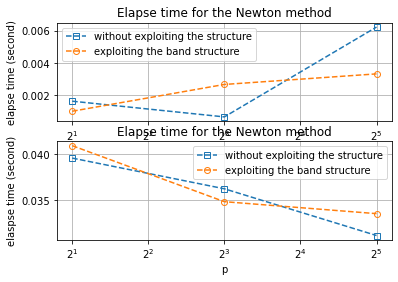

In [12]:
if __name__ == "__main__":
    ax = plt.subplot(2, 1, 1)
    plot_profiling_problem_one(ax)
    ax = plt.subplot(2, 1, 2)
    plot_profiling_problem_two(ax)
    plt.show()